In [ ]:
!pip install pyspark==3.5.3 pandas matplotlib

In [6]:
from google.colab import files
files.upload()   # elige el CSV, tarda un poco por los 85 MB

{}

# Sección nueva

Archivo: Reporte_Hurto_por_Modalidades_Policía_Nacional_20261019.csv
Filas: 656635
root
 |-- departamento: string (nullable = true)
 |-- municipio: string (nullable = true)
 |-- codigo_dane: integer (nullable = true)
 |-- armas_medios: string (nullable = true)
 |-- fecha_hecho: string (nullable = true)
 |-- genero: string (nullable = true)
 |-- grupo_etario: string (nullable = true)
 |-- tipo_de_hurto: string (nullable = true)
 |-- cantidad: integer (nullable = true)

Por tipo
+------------+------+
|tipo_hurto  |count |
+------------+------+
|MOTOCICLETAS|497736|
|AUTOMOTORES |158899|
+------------+------+

Top departamentos
+------------------+------+
|departamento      |count |
+------------------+------+
|ANTIOQUIA         |144040|
|BOGOTA            |113399|
|VALLE             |104537|
|CAUCA             |36692 |
|ATLÁNTICO         |33000 |
|HUILA             |20806 |
|NARIÑO            |19534 |
|NORTE DE SANTANDER|18719 |
|CESAR             |18497 |
|SANTANDER         |17530 |
+--

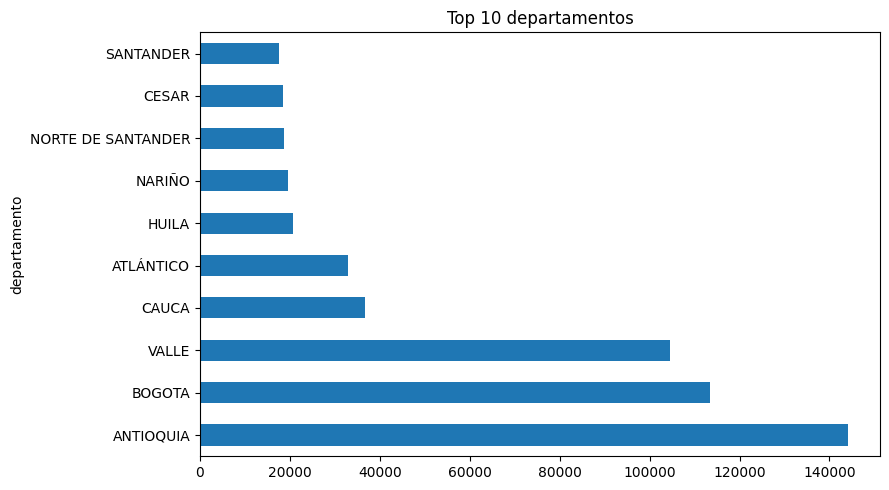

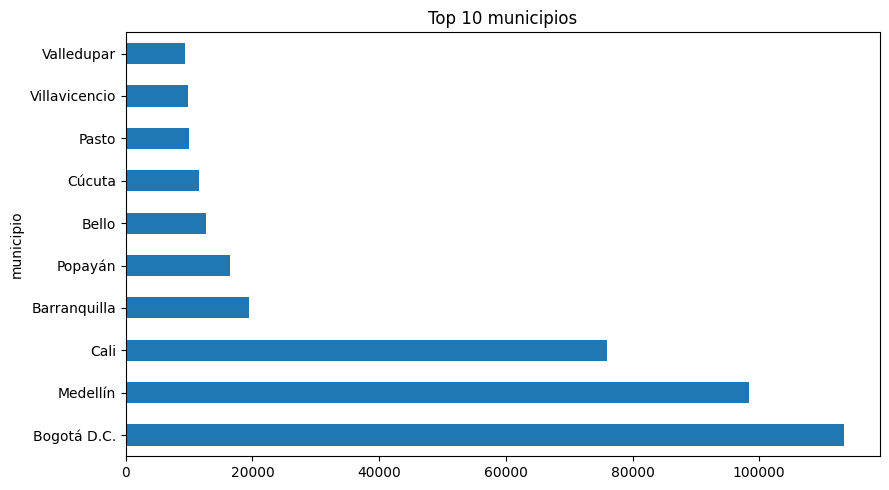

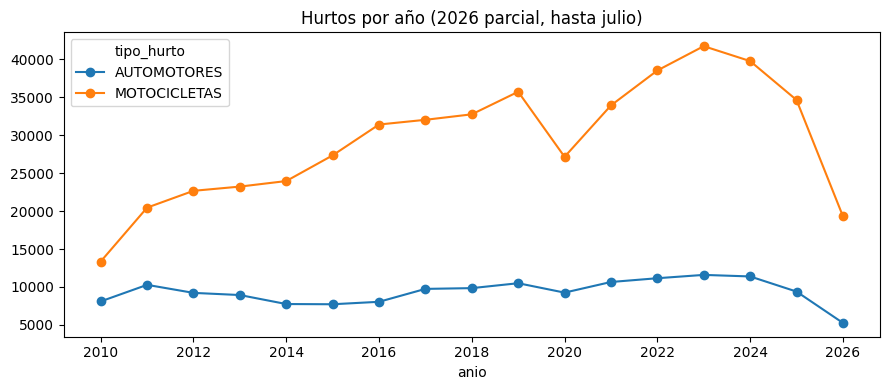

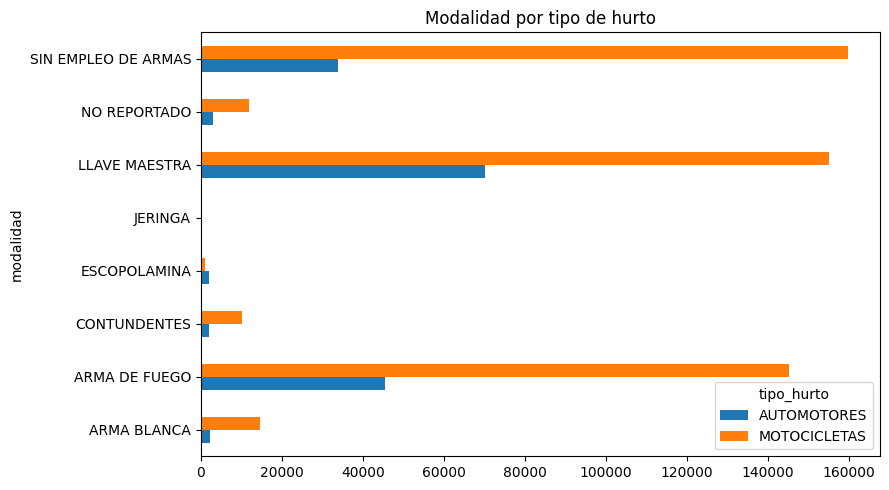

In [7]:
from pyspark.sql import SparkSession, functions as F
import matplotlib.pyplot as plt
import glob

spark = SparkSession.builder.appName("Hurtos_Vehiculos_Batch").getOrCreate()
spark.sparkContext.setLogLevel("WARN")
spark.conf.set("spark.sql.ansi.enabled", "false")

# ---------- 1. CARGA ----------
RUTA = glob.glob("*.csv")[0]
print("Archivo:", RUTA)
df = spark.read.csv(RUTA, header=True, inferSchema=True, encoding="UTF-8")
for c in df.columns:
    df = df.withColumnRenamed(c, c.strip().lower().replace(" ", "_"))
print("Filas:", df.count())
df.printSchema()

# ---------- 2. LIMPIEZA (sin dropDuplicates: cada fila es un evento) ----------
df = df.withColumn("fecha", F.to_date("fecha_hecho", "dd/MM/yyyy")).dropna(subset=["fecha"])

df = df.withColumn("tipo_hurto",
        F.when(F.col("tipo_de_hurto").contains("MOTOCICLETAS"), "MOTOCICLETAS")
         .otherwise("AUTOMOTORES"))

df = df.withColumn("municipio", F.trim(F.regexp_replace("municipio", r"\s*\(CT\)$", "")))

blanca = ["ARMA BLANCA / CORTOPUNZANTE", "ARMAS BLANCAS", "CORTANTES", "CORTOPUNZANTES", "PUNZANTES"]
df = df.withColumn("modalidad",
        F.when(F.col("armas_medios").isin(blanca), "ARMA BLANCA")
         .otherwise(F.col("armas_medios")))

df = df.fillna({"genero": "NO REPORTA", "grupo_etario": "NO REPORTADO"})

# ---------- 3. TRANSFORMACIÓN ----------
df = (df.withColumn("anio", F.year("fecha"))
        .withColumn("mes", F.month("fecha"))
        .withColumn("dia_semana", F.date_format("fecha", "E")))
df.cache()

# ---------- 4. EDA ----------
por_tipo = df.groupBy("tipo_hurto").count()
por_anio = df.groupBy("anio", "tipo_hurto").count().orderBy("anio")
top_deptos = df.groupBy("departamento").count().orderBy(F.desc("count")).limit(10)
top_mpios = df.groupBy("municipio").count().orderBy(F.desc("count")).limit(10)
modalidades = df.groupBy("modalidad", "tipo_hurto").count().orderBy(F.desc("count"))
por_dia = df.groupBy("dia_semana").count()
por_genero = df.groupBy("genero").count()

for n, t in [("Por tipo", por_tipo), ("Top departamentos", top_deptos),
             ("Top municipios", top_mpios), ("Modalidades", modalidades),
             ("Por día de la semana", por_dia), ("Por género", por_genero)]:
    print(n); t.show(truncate=False)

# ---------- 5. VISUALIZACIÓN ----------
def barras(sdf, x, titulo, archivo):
    p = sdf.toPandas()
    p.plot(kind="barh", x=x, y="count", legend=False, figsize=(9, 5))
    plt.title(titulo); plt.tight_layout(); plt.savefig(archivo); plt.show()

barras(top_deptos, "departamento", "Top 10 departamentos", "top_deptos.png")
barras(top_mpios, "municipio", "Top 10 municipios", "top_municipios.png")

p = por_anio.toPandas().pivot(index="anio", columns="tipo_hurto", values="count")
p.plot(marker="o", figsize=(9, 4))
plt.title("Hurtos por año (2026 parcial, hasta julio)")
plt.tight_layout(); plt.savefig("serie_anual.png"); plt.show()

m = modalidades.toPandas().pivot(index="modalidad", columns="tipo_hurto", values="count").fillna(0)
m.plot(kind="barh", figsize=(9, 5))
plt.title("Modalidad por tipo de hurto"); plt.tight_layout()
plt.savefig("modalidades.png"); plt.show()

In [8]:
from google.colab import files
for f in ["serie_anual.png", "top_deptos.png", "top_municipios.png", "modalidades.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Sección nueva

In [4]:
!ls -lh *.csv

-rw-r--r-- 1 root root 81M Oct 28 22:50 'Reporte_Hurto_por_Modalidades_Policía_Nacional_20261019 (1).csv'
-rw-r--r-- 1 root root 81M Oct 28 22:42  Reporte_Hurto_por_Modalidades_Policía_Nacional_20261019.csv


# Sección nueva

In [5]:
!rm "Reporte_Hurto_por_Modalidades_Policía_Nacional_20261019 (1).csv"
!ls -lh *.csv

-rw-r--r-- 1 root root 81M Oct 28 22:42 Reporte_Hurto_por_Modalidades_Policía_Nacional_20261019.csv
